<div align="center">

               UNIVERSIDAD NACIONAL DEL CENTRO DEL PERÚ
                  Facultad de Ingeniería de Sistemas
                  INGENIERÍA DEL CONOCIMIENTO (ISO56B)
**Actividad 1: Pipeline de Machine Learning Clásico sobre Dataset Real**

</div>

---
# SECCIÓN A — Presentación

**A.1 Curso, semestre y fecha**

| Curso | Semestre | Docente | Fecha |
|---|---|---|---|
| Ingeniería del Conocimiento (ISO56B) | 2026-II | Msc. Jaime Antonio Huaytalla Pariona | ___ / ___ / 2026 |

**A.2 Integrantes**

| N.º | Apellidos y nombres | Código |
|:-:|---|---|
| 1 | Acevedo Pomayay Jean Pool THair | 2024200178I |
| 2 | Rouviros Santacroce Eduardo | 2024200204I |
| 3 | Renzo Styp Loyola Rodriguez | 2024200192J |
| 4 | Gino Paoli Alfaro Victoria | 2024200179J |

**A.3 Dataset elegido**

- **Nombre:** Pokémon Dataset — Generaciones I a IX.
- **Fuente (URL):** Kaggle — https://www.kaggle.com/datasets/ceebloop/pokmon-dataset-2024 .
- **Justificación:** cumple los requisitos mínimos (es **tabular de clasificación**, tiene **1 025 registros** y **17 columnas** (16 variables predictoras y una objetivo), **2 clases** y son **datos reales** de los juegos oficiales). Además, sus clases están **desbalanceadas** (solo 7 % de legendarios), lo que nos permite aplicar los conceptos del curso: estratificación, F1-score, recall y AUC.

**A.4 Descripción del problema**

Queremos predecir si un Pokémon es **legendario** (`is_legendary = True`) o **no legendario** usando sus **6 estadísticas de combate** (vida, ataque, defensa, ataque especial, defensa especial y velocidad) y sus **tipos** (Agua, Fuego, etc.). Es un problema de **clasificación binaria** con **clases desbalanceadas**: hay 71 legendarios frente a 954 no legendarios. Lo importante no es solo acertar en general, sino **detectar a los pocos legendarios** sin dar demasiadas falsas alarmas.


---
# SECCIÓN B — Carga y Análisis Exploratorio de Datos (EDA)
**Librerías y semilla.** Fijamos `SEED = 42` para que los resultados sean **reproducibles** (siempre salen los mismos números).

In [33]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, classification_report, confusion_matrix)

import warnings
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
COLORES = {"No legendario": "#4C72B0", "Legendario": "#DD8452"}

### B.1 Carga del dataset
En este apartado subimos la base de datos al Colab.
La base de datos es sobre pokemon.


La url de la base de datos es: https://www.kaggle.com/datasets/ceebloop/pokmon-dataset-2024

In [34]:
RUTA = "datos_ing_conocimiento.xlsx"
if not os.path.exists(RUTA):                 # en Colab: pedir el archivo
    from google.colab import files
    RUTA = list(files.upload().keys())[0]

df = pd.read_excel(RUTA, sheet_name="pokemon_dataset")

# Arreglo de tildes mal codificadas (ej. 'PokÃ©mon' → 'Pokémon')
def corregir_texto(s):
    if isinstance(s, str):
        for codif in ("cp1252", "latin-1"):
            try:
                return s.encode(codif).decode("utf-8")
            except (UnicodeEncodeError, UnicodeDecodeError):
                pass
    return s
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].map(corregir_texto)

# Columna con el nombre de la clase (solo para gráficos)
df["clase"] = df["is_legendary"].map({True: "Legendario", False: "No legendario"})
print(f"Dataset cargado: {df.shape[0]} filas")

Dataset cargado: 1025 filas


In [35]:
# VERIFICACIÓN DE LA BASE DE DATOS

print("1. DIMENSIONES:")
print(df.shape)

print("\n2. COLUMNAS:")
print(df.columns.tolist())

print("\n3. DISTRIBUCIÓN DE CLASES:")
print(df["is_legendary"].value_counts(dropna=False))

print("\n4. VALORES NULOS:")
print(df.isnull().sum())

print("\n5. FILAS DUPLICADAS:")
print(
    df.drop(columns=["clase"], errors="ignore")
      .duplicated().sum()
)

1. DIMENSIONES:
(1025, 18)

2. COLUMNAS:
['dex_number', 'name', 'type_01', 'type_02', 'ability_01', 'ability_02', 'hidden_ability', 'egg_group_01', 'egg_group_02', 'is_legendary', 'bio', 'hp', 'attack', 'defense', 'sp_attack', 'sp_defense', 'speed', 'clase']

3. DISTRIBUCIÓN DE CLASES:
is_legendary
False    954
True      71
Name: count, dtype: int64

4. VALORES NULOS:
dex_number          0
name                0
type_01             0
type_02           499
ability_01          0
ability_02        495
hidden_ability    169
egg_group_01      120
egg_group_02      745
is_legendary        0
bio                 0
hp                  0
attack              0
defense             0
sp_attack           0
sp_defense          0
speed               0
clase               0
dtype: int64

5. FILAS DUPLICADAS:
0


### B.2 Primeras filas, *shape*, tipos de datos y valores nulos

In [36]:
display(df.drop(columns="clase").head())
print(f"Shape: {df.drop(columns='clase').shape}  →  1 025 filas y 17 columnas (16 variables + 1 objetivo)")

,dex_number,name,type_01,type_02,ability_01,ability_02,hidden_ability,egg_group_01,egg_group_02,is_legendary,bio,hp,attack,defense,sp_attack,sp_defense,speed
0,#0001,Bulbasaur,Grass,Poison,Overgrow,NaN,Chlorophyll,Monster,Grass,False,Bulbasaur is a dual-type Grass/Poison Pokémon ...,45,49,49,65,65,45
1,#0002,Ivysaur,Grass,Poison,Overgrow,NaN,Chlorophyll,Monster,Grass,False,Ivysaur is a dual-type Grass/Poison Pokémon in...,60,62,63,80,80,60
2,#0003,Venusaur,Grass,Poison,Overgrow,NaN,Chlorophyll,Monster,Grass,False,Venusaur is a dual-type Grass/Poison Pokémon i...,80,82,83,100,100,80
3,#0004,Charmander,Fire,NaN,Blaze,NaN,Solar Power,Monster,Dragon,False,Charmander is a Fire-type Pokémon introduced i...,39,52,43,60,50,65
4,#0005,Charmeleon,Fire,NaN,Blaze,NaN,Solar Power,Monster,Dragon,False,Charmeleon is a Fire-type Pokémon introduced i...,58,64,58,80,65,80


Shape: (1025, 17)  →  1 025 filas y 17 columnas (16 variables + 1 objetivo)


In [37]:
info = pd.DataFrame({
    "Tipo de dato": df.drop(columns="clase").dtypes.astype(str),
    "Valores nulos": df.drop(columns="clase").isna().sum(),
    "% nulos": (df.drop(columns="clase").isna().mean() * 100).round(1),
})
display(info)

,Tipo de dato,Valores nulos,% nulos
dex_number,object,0,0.0
name,object,0,0.0
type_01,object,0,0.0
type_02,object,499,48.7
ability_01,object,0,0.0
ability_02,object,495,48.3
hidden_ability,object,169,16.5
egg_group_01,object,120,11.7
egg_group_02,object,745,72.7
is_legendary,bool,0,0.0


Hay 6 columnas numéricas (las estadísticas), 10 de texto y la variable objetivo `is_legendary` (booleana). **Las estadísticas no tienen nulos.** Los nulos están en `type_02`, `ability_02`, `hidden_ability` y los `egg_group`; los analizamos en B.5.4.

### B.3 Distribución de la variable objetivo

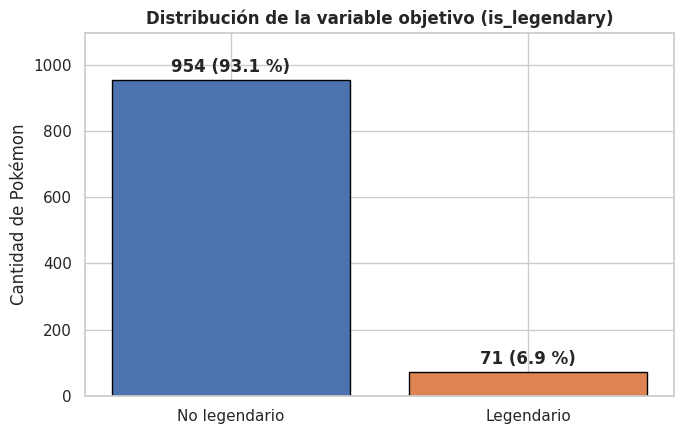

In [38]:
conteo = df["clase"].value_counts()
porc = df["clase"].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(7, 4.5))
barras = ax.bar(conteo.index, conteo.values, color=[COLORES[c] for c in conteo.index], edgecolor="black")
ax.bar_label(barras, labels=[f"{n} ({p:.1f} %)" for n, p in zip(conteo.values, porc.values)],
             padding=3, fontsize=12, fontweight="bold")
ax.set_ylim(0, conteo.max() * 1.15)
ax.set_ylabel("Cantidad de Pokémon")
ax.set_title("Distribución de la variable objetivo (is_legendary)", fontweight="bold")
plt.tight_layout()
plt.show()

**Lectura:** solo el **6.9 %** son legendarios (1 de cada 14). Por eso:
- El **accuracy engaña**: un modelo que diga siempre "No legendario" acertaría el 93 % sin encontrar ningún legendario. Usaremos **F1-macro**, **recall** y **AUC**.
- El *split* train/test será **estratificado** y usaremos `class_weight="balanced"` en los modelos que lo permitan.

### B.4 Estadísticas descriptivas de las variables numéricas
Agregamos la variable **`total`** = suma de las 6 estadísticas (mide el "poder total" del Pokémon).

In [39]:
STATS = ["hp", "attack", "defense", "sp_attack", "sp_defense", "speed"]
df["total"] = df[STATS].sum(axis=1)
NUMERICAS = STATS + ["total"]

display(df[NUMERICAS].describe().round(1))

,hp,attack,defense,sp_attack,sp_defense,speed,total
count,1025.0,1025.0,1025.0,1025.0,1025.0,1025.0,1025.0
mean,70.1,77.4,72.4,70.0,70.1,67.1,427.0
std,26.7,29.7,29.4,29.6,26.7,28.7,112.8
min,1.0,5.0,5.0,10.0,20.0,5.0,175.0
25%,50.0,55.0,50.0,47.0,50.0,45.0,325.0
50%,67.0,75.0,70.0,65.0,65.0,65.0,450.0
75%,85.0,100.0,90.0,90.0,85.0,88.0,505.0
max,255.0,181.0,230.0,173.0,230.0,200.0,720.0


**Lectura:** las estadísticas van de 1 a 255 y `total` de 175 a 720, es decir, **están en escalas distintas** → habrá que escalar. Los máximos (`hp` = 255, `defense` = 230) están muy lejos del promedio (≈ 70): son **valores atípicos**.

### B.5 Visualizaciones adicionales

#### B.5.1 Histogramas: ¿en qué se diferencian los legendarios?

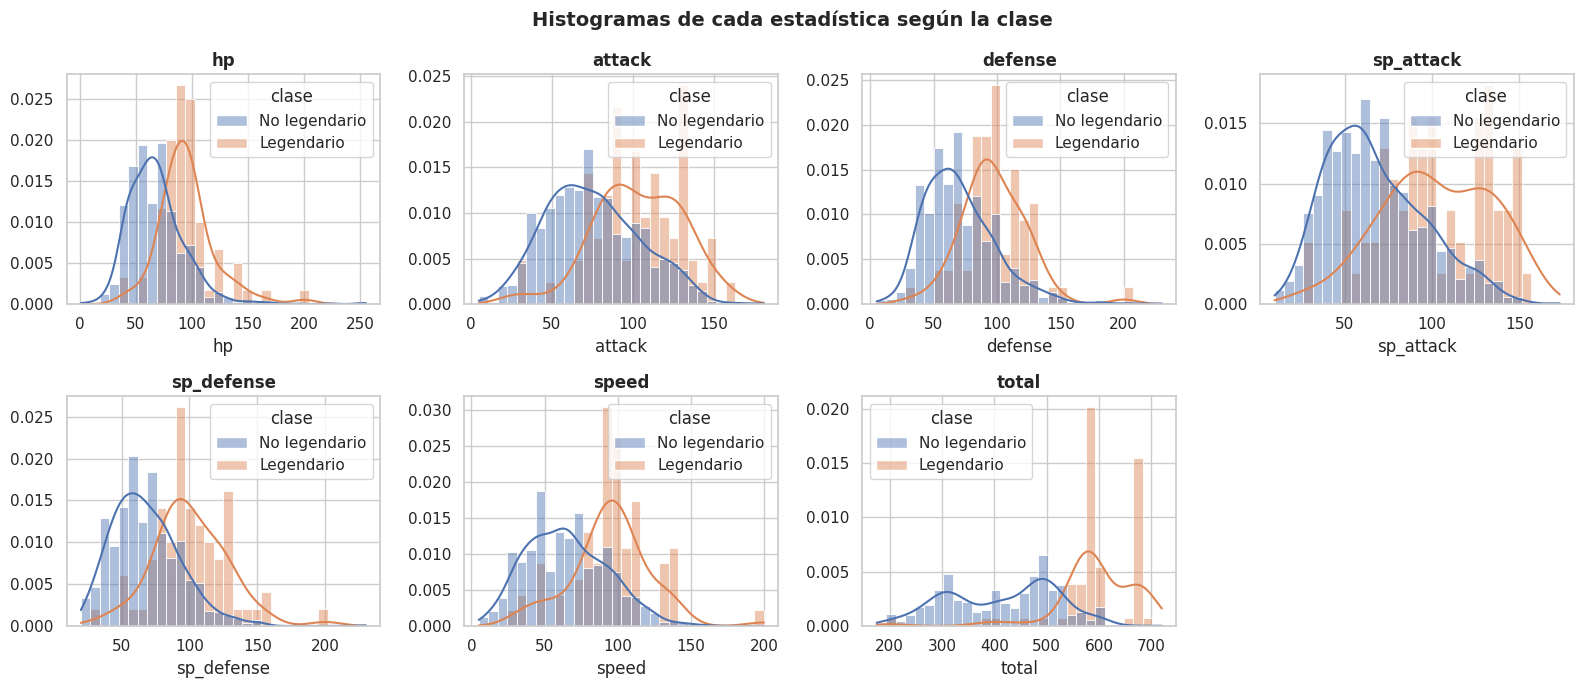

In [40]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), NUMERICAS):
    sns.histplot(data=df, x=col, hue="clase", stat="density", common_norm=False,
                 kde=True, bins=30, palette=COLORES, alpha=0.45, ax=ax)
    ax.set_title(col, fontweight="bold"); ax.set_ylabel("")
axes.ravel()[-1].axis("off")
fig.suptitle("Histogramas de cada estadística según la clase", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Lectura:** en todas las estadísticas los legendarios (naranja) están **más a la derecha**. La que mejor los separa es **`total`**: casi todos los legendarios tienen entre 570 y 720. Pero hay **zonas donde se mezclan** (Pokémon normales muy fuertes y legendarios débiles), por eso necesitamos un modelo y no basta una regla simple.

#### B.5.2 Boxplots: valores atípicos

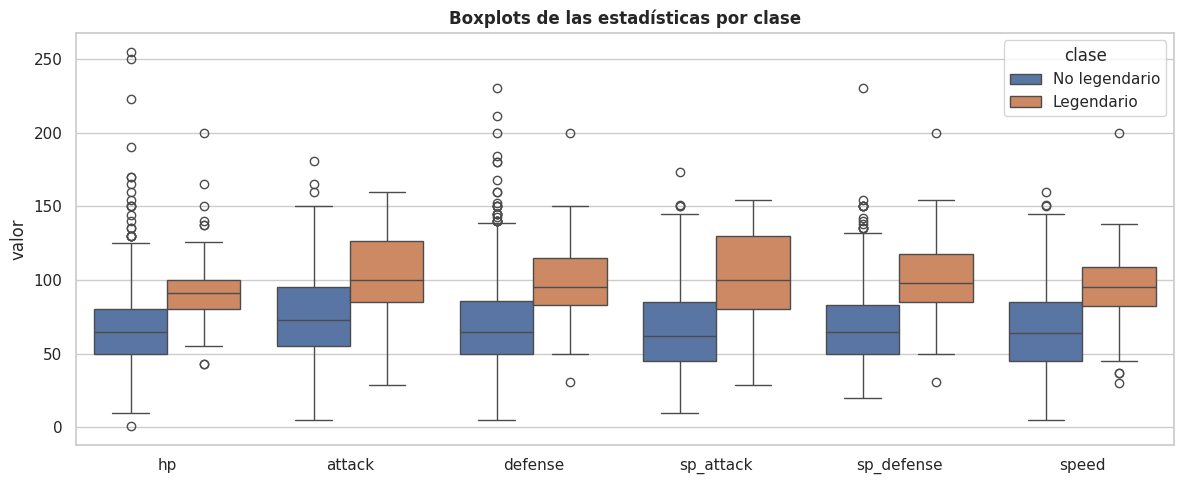

Máximo de hp: 255 → Blissey
Máximo de defense: 230 → Shuckle


In [41]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=df.melt(id_vars="clase", value_vars=STATS, var_name="estadística", value_name="valor"),
            x="estadística", y="valor", hue="clase", palette=COLORES, ax=ax)
ax.set_title("Boxplots de las estadísticas por clase", fontweight="bold"); ax.set_xlabel("")
plt.tight_layout()
plt.show()

for col in ["hp", "defense"]:
    fila = df.loc[df[col].idxmax()]
    print(f"Máximo de {col}: {fila[col]} → {fila['name']}")

**Lectura:** Los puntos aislados representan valores atípicos reales: Blissey tiene `hp = 255` y Shuckle `defense = 230`. No se eliminan porque son características válidas del dataset. Se aplicará `StandardScaler` para estandarizar las variables, considerando que también es sensible a valores extremos.

#### B.5.3 Matriz de correlación

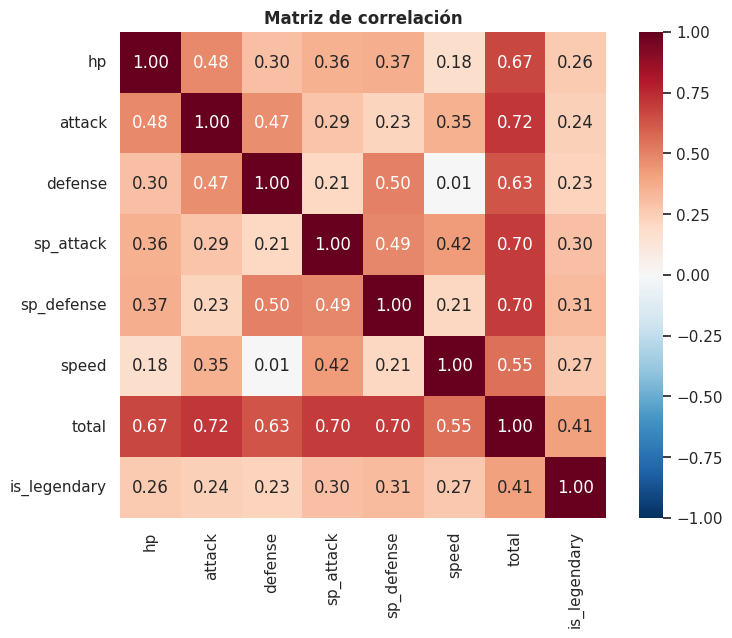

In [42]:
corr = df[NUMERICAS].assign(is_legendary=df["is_legendary"].astype(int)).corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Matriz de correlación", fontweight="bold")
plt.tight_layout()
plt.show()

**Lectura:** la variable más relacionada con `is_legendary` es **`total` (0.41)**, seguida de `sp_defense` y `sp_attack` (≈ 0.30). Ninguna supera 0.5, lo que confirma que **ninguna variable sola basta** para predecir.

#### B.5.4 Nulos por clase: ¿hay columnas que "delatan" la respuesta?

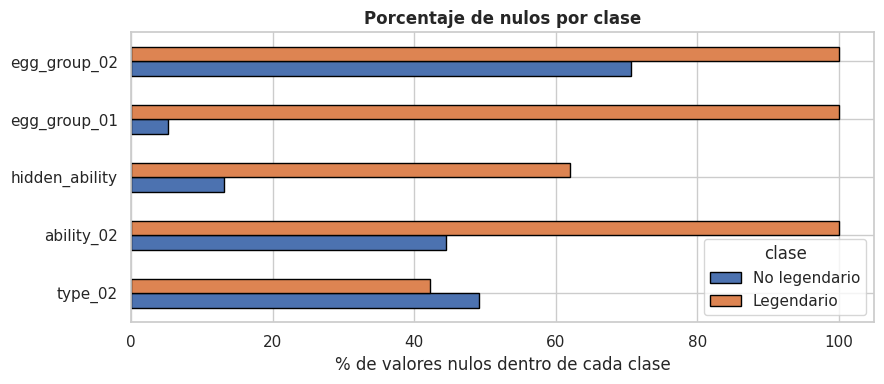

clase,No legendario,Legendario
type_02,49.2,42.3
ability_02,44.4,100.0
hidden_ability,13.1,62.0
egg_group_01,5.1,100.0
egg_group_02,70.6,100.0


In [43]:
COLS_NULOS = ["type_02", "ability_02", "hidden_ability", "egg_group_01", "egg_group_02"]
nulos_clase = pd.DataFrame({c: df.groupby("clase")[c].apply(lambda s: s.isna().mean() * 100)
                            for c in COLS_NULOS}).T[["No legendario", "Legendario"]]

fig, ax = plt.subplots(figsize=(9, 4))
nulos_clase.plot(kind="barh", ax=ax, color=[COLORES["No legendario"], COLORES["Legendario"]],
                 edgecolor="black")
ax.set_xlabel("% de valores nulos dentro de cada clase")
ax.set_title("Porcentaje de nulos por clase", fontweight="bold")
plt.tight_layout()
plt.show()
display(nulos_clase.round(1))

**Lectura — fuga de datos (*data leakage*):** `egg_group_01`, `egg_group_02` y `ability_02` están **vacíos en el 100 % de los legendarios**. Si las usáramos, el modelo aprendería la "trampa" *"si está vacío → legendario"* y tendría métricas casi perfectas sin aprender nada útil. Estas columnas son **consecuencia** de ser legendario (en el juego, a los legendarios no se les asigna grupo huevo), no una característica para predecirlo. **Por eso las eliminamos.**

### B.6 Conclusiones del EDA
El dataset tiene 1 025 Pokémon sin filas duplicadas y sin nulos en las estadísticas, pero con un **fuerte desbalance** (6.9 % legendarios), por lo que usaremos división estratificada, `class_weight="balanced"` y métricas como F1-macro, recall y AUC en lugar del accuracy. La variable más útil es **`total`** (correlación 0.41), aunque las clases se mezclan en parte, lo que justifica usar modelos de *machine learning*. Las estadísticas tienen **escalas distintas y atípicos reales**, así que aplicaremos `StandardScaler` sin eliminar filas. Detectamos **fuga de datos** en `egg_group_01`, `egg_group_02` y `ability_02`, que eliminaremos junto con las columnas de texto libre. Finalmente, `type_02` tiene nulos que significan "tiene un solo tipo": los imputaremos con `"Ninguno"` y codificaremos los tipos con **one-hot** (`get_dummies`).

---
# SECCIÓN C — Preprocesamiento

### C.1 Tratamiento de valores nulos

| Columna | Decisión | Justificación |
|---|---|---|
| `type_02` (499 nulos) | **Imputar con `"Ninguno"`** | El nulo significa que el Pokémon tiene un solo tipo: es información válida. Si elimináramos esas filas perderíamos la mitad del dataset. |
| `egg_group_01`, `egg_group_02`, `ability_02` | **Eliminar columna** | Fuga de datos (B.5.4). |
| `hidden_ability`, `ability_01` | **Eliminar columna** | Texto con cientos de valores distintos y cortado (ej. `"Keen"` en vez de *Keen Eye*). |
| `bio` | **Eliminar columna** | Es una descripción que menciona la palabra *"Legendary"*: también es fuga. |
| `dex_number`, `name` | **Eliminar columna** | Son identificadores, no características. |

In [44]:
df_modelo = df.drop(columns=["dex_number", "name", "bio", "ability_01", "ability_02",
                             "hidden_ability", "egg_group_01", "egg_group_02", "clase"])
df_modelo["type_02"] = df_modelo["type_02"].fillna("Ninguno")

print("Columnas que quedan:", list(df_modelo.columns))
print("Nulos restantes:", df_modelo.isna().sum().sum())

Columnas que quedan: ['type_01', 'type_02', 'is_legendary', 'hp', 'attack', 'defense', 'sp_attack', 'sp_defense', 'speed', 'total']
Nulos restantes: 0


### C.2 Codificación de variables categóricas
- **`type_01` y `type_02`** → **One-hot con `pd.get_dummies`**: crea una columna 0/1 por cada tipo (ej. `type_01_Fire` = 1 si su tipo principal es Fuego). No usamos `LabelEncoder` aquí porque convertiría los tipos en números 0, 1, 2… y el modelo creería que existe un orden (Agua < Fuego < Planta), lo cual es falso.
- **`is_legendary`** (objetivo) → **`LabelEncoder`**: `False` → 0, `True` → 1.

In [45]:
X = pd.get_dummies(df_modelo.drop(columns="is_legendary"), columns=["type_01", "type_02"], dtype=int)

le = LabelEncoder()
y = le.fit_transform(df_modelo["is_legendary"])
print("Codificación del objetivo: False → 0 (No legendario), True → 1 (Legendario)")
print(f"Matriz X: {X.shape[0]} filas × {X.shape[1]} columnas "
      f"(7 numéricas + {X.shape[1] - 7} columnas one-hot de tipos)")
display(X.iloc[:3, :12])

Codificación del objetivo: False → 0 (No legendario), True → 1 (Legendario)
Matriz X: 1025 filas × 44 columnas (7 numéricas + 37 columnas one-hot de tipos)


,hp,attack,defense,sp_attack,sp_defense,speed,total,type_01_Bug,type_01_Dark,type_01_Dragon,type_01_Electric,type_01_Fairy
0,45,49,49,65,65,45,318,0,0,0,0,0
1,60,62,63,80,80,60,405,0,0,0,0,0
2,80,82,83,100,100,80,525,0,0,0,0,0


### C.3 Escalado: `StandardScaler`

Se estandarizan las 7 variables numéricas mediante `StandardScaler`. Las variables codificadas con One-Hot permanecen en valores 0 y 1.

**¿Por qué `StandardScaler` y no `MinMaxScaler`?**

1. **Por la distribución de los datos:** `StandardScaler` utiliza la media y desviación estándar, mientras que `MinMaxScaler` utiliza los valores mínimo y máximo. Ambos son sensibles a valores atípicos, pero `MinMaxScaler` puede comprimir los valores habituales cuando existen extremos.
2. **Por los modelos:** Regresión Logística, SVM y KNN se benefician de variables con escalas comparables. Sin escalado, características como `total` podrían influir excesivamente debido a su magnitud.

**Importante:** el escalador se ajusta únicamente con los datos de entrenamiento (`train`) y luego se aplica a `test`, evitando utilizar información estadística del conjunto de prueba durante el ajuste.

In [46]:
NUM_COLS = NUMERICAS          # 6 estadísticas + total
escalador = ColumnTransformer([("num", StandardScaler(), NUM_COLS)],
                              remainder="passthrough", verbose_feature_names_out=False)

### C.4 Split train/test estratificado (`test_size=0.2`, `random_state=42`)

In [47]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

X_train_esc = escalador.fit_transform(X_train)   # fit SOLO con train
X_test_esc  = escalador.transform(X_test)        # test solo se transforma

print(f"Train: {X_train.shape[0]} filas | Test: {X_test.shape[0]} filas")
print(f"Media de 'total' escalado en train: {X_train_esc[:, 6].mean():.2f}, "
      f"desviación: {X_train_esc[:, 6].std():.2f}")

Train: 820 filas | Test: 205 filas
Media de 'total' escalado en train: -0.00, desviación: 1.00


### C.5 Verificación de la distribución de clases en train y test

In [48]:
verif = pd.DataFrame({
    "Train (n)": np.bincount(y_train), "Train (%)": np.bincount(y_train) / len(y_train) * 100,
    "Test (n)":  np.bincount(y_test),  "Test (%)":  np.bincount(y_test) / len(y_test) * 100,
}, index=["No legendario", "Legendario"]).round(2)
display(verif)

,Train (n),Train (%),Test (n),Test (%)
No legendario,763,93.05,191,93.17
Legendario,57,6.95,14,6.83


**Lectura:** gracias a `stratify=y`, train y test tienen **casi el mismo % de legendarios (≈ 6.9 %)** que el dataset completo. Sin estratificar, con solo 71 legendarios, el azar podría dejar muy pocos en test y la evaluación no sería confiable.

---
# SECCIÓN D — Modelado


| Modelo | Idea en una línea | Parámetros usados |
|---|---|---|
| Regresión Logística | Traza una frontera recta y da una probabilidad. | `class_weight="balanced"` |
| Árbol de Decisión | Hace preguntas *si/no* (ej. ¿total > 570?). | `max_depth=6` para que no memorice, `class_weight="balanced"` |
| Random Forest | Vota con 300 árboles distintos. | `n_estimators=300`, `class_weight="balanced"` |
| SVM | Busca la frontera con el mayor margen; con kernel RBF puede ser curva. | `kernel="rbf"`, `class_weight="balanced"` |
| KNN | Mira a los 5 vecinos más parecidos y vota. | `n_neighbors=5` |
| Gradient Boosting | Árboles en cadena: cada uno corrige los errores del anterior. | Por defecto (100 árboles) |

**Cómo leer las métricas** (clase "Legendario"):
- **Precision:** de los que el modelo dijo "Legendario", ¿cuántos lo eran?
- **Recall:** de todos los legendarios reales, ¿cuántos encontró?
- **F1-score:** equilibrio entre precision y recall.
- **Matriz de confusión:** diagonal = aciertos; abajo a la izquierda = legendarios que **se le escaparon**; arriba a la derecha = **falsas alarmas**.

In [49]:
NOMBRES = ["No legendario", "Legendario"]
resultados, modelos = {}, {}

def evaluar_modelo(nombre, modelo):
    modelo.fit(X_train_esc, y_train)                    # 1) entrenar con train
    y_pred  = modelo.predict(X_test_esc)                # 2) predecir sobre test
    y_proba = modelo.predict_proba(X_test_esc)[:, 1]
    resultados[nombre] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro"),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro"),
        "F1 (macro)": f1_score(y_test, y_pred, average="macro"),
        "Recall legendario": recall_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_proba),
    }
    modelos[nombre] = modelo

    print(f"===== {nombre} =====")                    # 3) métricas
    print(classification_report(y_test, y_pred, target_names=NOMBRES, digits=3))

    cm = confusion_matrix(y_test, y_pred)               # 4) matriz de confusión
    fig, ax = plt.subplots(figsize=(4.8, 3.8))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=NOMBRES, yticklabels=NOMBRES, annot_kws={"fontsize": 14})
    ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
    ax.set_title(f"Matriz de confusión — {nombre}", fontweight="bold")
    plt.tight_layout()
    plt.show()
    print(f"→ Encontró {cm[1,1]} de {cm[1].sum()} legendarios y dio {cm[0,1]} falsas alarmas.")

### D.1 Regresión Logística

===== Regresión Logística =====
               precision    recall  f1-score   support

No legendario      0.994     0.880     0.933       191
   Legendario      0.361     0.929     0.520        14

     accuracy                          0.883       205
    macro avg      0.678     0.904     0.727       205
 weighted avg      0.951     0.883     0.905       205



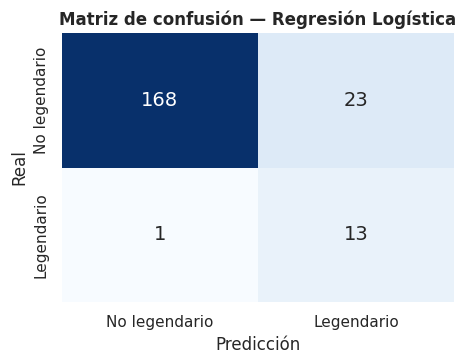

→ Encontró 13 de 14 legendarios y dio 23 falsas alarmas.


In [50]:
evaluar_modelo("Regresión Logística", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED))

### D.2 Árbol de Decisión

===== Árbol de Decisión =====
               precision    recall  f1-score   support

No legendario      0.983     0.901     0.940       191
   Legendario      0.367     0.786     0.500        14

     accuracy                          0.893       205
    macro avg      0.675     0.843     0.720       205
 weighted avg      0.941     0.893     0.910       205



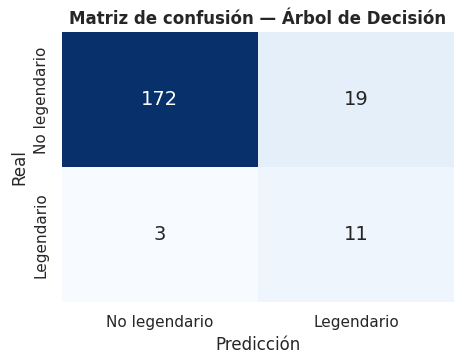

→ Encontró 11 de 14 legendarios y dio 19 falsas alarmas.


In [51]:
evaluar_modelo("Árbol de Decisión", DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=SEED))

### D.3 Random Forest

===== Random Forest =====
               precision    recall  f1-score   support

No legendario      0.964     0.990     0.977       191
   Legendario      0.778     0.500     0.609        14

     accuracy                          0.956       205
    macro avg      0.871     0.745     0.793       205
 weighted avg      0.952     0.956     0.952       205



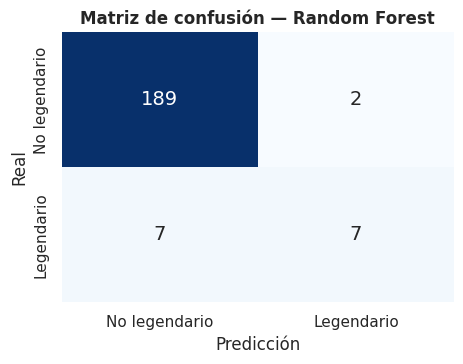

→ Encontró 7 de 14 legendarios y dio 2 falsas alarmas.


In [52]:
evaluar_modelo("Random Forest", RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED))

### D.4 SVM (kernel RBF)

===== SVM =====
               precision    recall  f1-score   support

No legendario      0.983     0.932     0.957       191
   Legendario      0.458     0.786     0.579        14

     accuracy                          0.922       205
    macro avg      0.721     0.859     0.768       205
 weighted avg      0.948     0.922     0.931       205



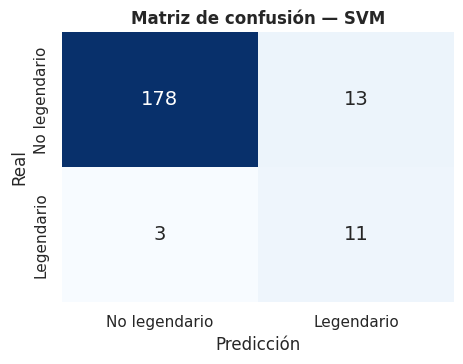

→ Encontró 11 de 14 legendarios y dio 13 falsas alarmas.


In [53]:
evaluar_modelo("SVM", SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=SEED))

### D.5 KNN

===== KNN =====
               precision    recall  f1-score   support

No legendario      0.949     0.984     0.967       191
   Legendario      0.571     0.286     0.381        14

     accuracy                          0.937       205
    macro avg      0.760     0.635     0.674       205
 weighted avg      0.924     0.937     0.927       205



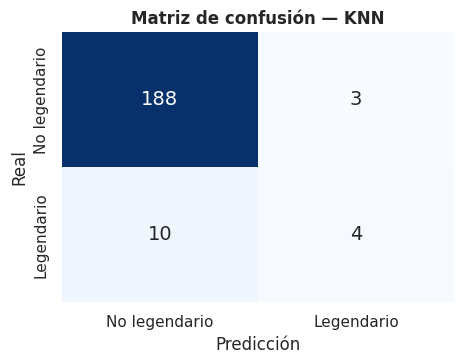

→ Encontró 4 de 14 legendarios y dio 3 falsas alarmas.


In [54]:
evaluar_modelo("KNN", KNeighborsClassifier(n_neighbors=5))

### D.6 Gradient Boosting

===== Gradient Boosting =====
               precision    recall  f1-score   support

No legendario      0.974     0.990     0.982       191
   Legendario      0.818     0.643     0.720        14

     accuracy                          0.966       205
    macro avg      0.896     0.816     0.851       205
 weighted avg      0.964     0.966     0.964       205



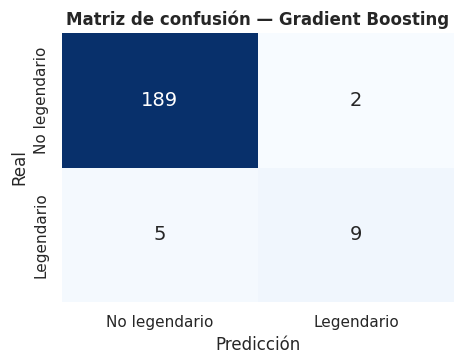

→ Encontró 9 de 14 legendarios y dio 2 falsas alarmas.


In [55]:
evaluar_modelo("Gradient Boosting", GradientBoostingClassifier(random_state=SEED))

---
# SECCIÓN E — Evaluación Comparativa


### E.1 Tabla resumen de métricas (ordenada por F1-macro)

In [56]:
tabla = pd.DataFrame(resultados).T.sort_values("F1 (macro)", ascending=False).round(3)
display(tabla)

,Accuracy,Precision (macro),Recall (macro),F1 (macro),Recall legendario,AUC
Gradient Boosting,0.966,0.896,0.816,0.851,0.643,0.948
Random Forest,0.956,0.871,0.745,0.793,0.500,0.968
SVM,0.922,0.721,0.859,0.768,0.786,0.936
Regresión Logística,0.883,0.678,0.904,0.727,0.929,0.912
Árbol de Decisión,0.893,0.675,0.843,0.720,0.786,0.851
KNN,0.937,0.760,0.635,0.674,0.286,0.839


### E.2 Gráfico de barras comparando los modelos

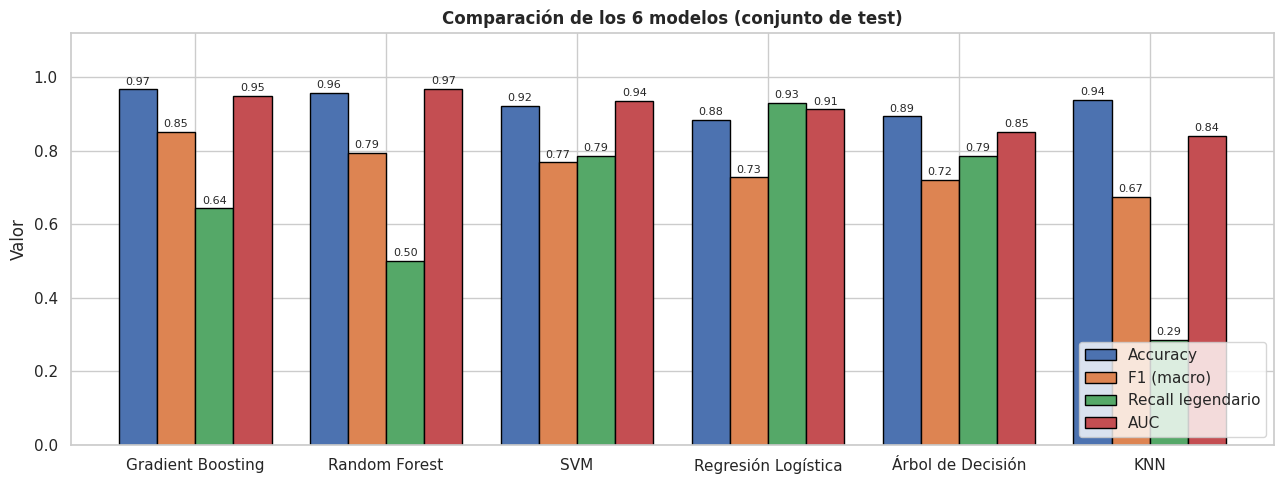

In [57]:
fig, ax = plt.subplots(figsize=(13, 5))
tabla[["Accuracy", "F1 (macro)", "Recall legendario", "AUC"]].plot(
    kind="bar", ax=ax, rot=0, edgecolor="black", width=0.8)
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.2f", fontsize=8, padding=2)
ax.set_ylim(0, 1.12); ax.set_ylabel("Valor")
ax.set_title("Comparación de los 6 modelos (conjunto de test)", fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### E.3 Curvas ROC superpuestas
La curva ROC muestra qué tan bien separa el modelo las dos clases **para todos los umbrales posibles**. Mientras más se acerque a la esquina superior izquierda, mejor. El **AUC** (área bajo la curva) va de 0.5 (azar) a 1.0 (perfecto).

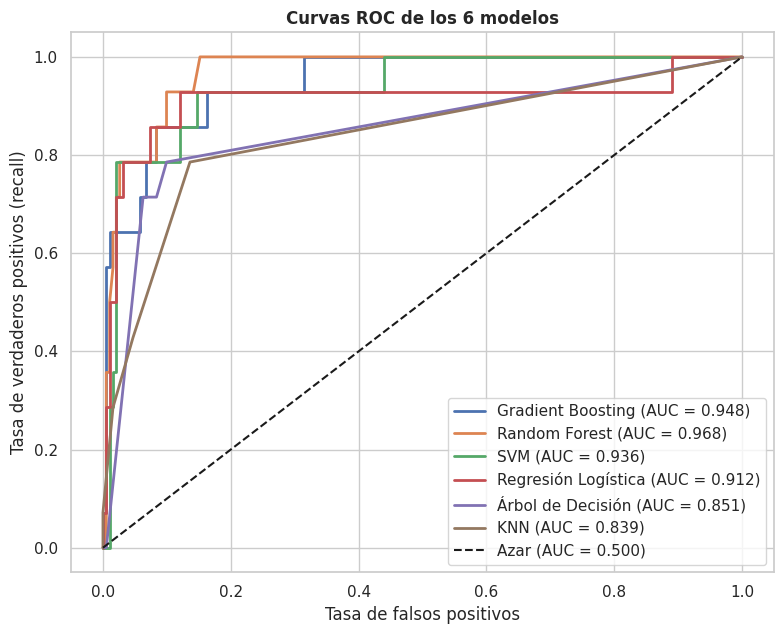

In [58]:
fig, ax = plt.subplots(figsize=(8, 6.5))
for nombre in tabla.index:
    proba = modelos[nombre].predict_proba(X_test_esc)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, lw=2, label=f"{nombre} (AUC = {tabla.loc[nombre, 'AUC']:.3f})")
ax.plot([0, 1], [0, 1], "k--", label="Azar (AUC = 0.500)")
ax.set_xlabel("Tasa de falsos positivos"); ax.set_ylabel("Tasa de verdaderos positivos (recall)")
ax.set_title("Curvas ROC de los 6 modelos", fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### E.4 Análisis: ¿cuál es el mejor modelo y por qué?

El modelo con mejor rendimiento general fue **Gradient Boosting**, con el F1-macro más alto (0.851) y una accuracy de 96.6 %. Identificó correctamente 9 de los 14 Pokémon legendarios, generando únicamente 2 falsas alarmas. Su principal limitación fue el recall de legendarios (0.643), ya que no detectó 5 de ellos.

**Random Forest** obtuvo un F1-macro de 0.793 y el mayor AUC (0.968), pero identificó solamente 7 de los 14 legendarios, con 2 falsas alarmas. Por otro lado, la **Regresión Logística** alcanzó el mayor recall de legendarios (0.929), detectando 13 de 14, aunque generó 23 falsas alarmas. **KNN** obtuvo una accuracy de 93.7 %, pero identificó apenas 4 legendarios, demostrando que el accuracy puede resultar engañoso en datasets desbalanceados.

**En conclusión**, Gradient Boosting presentó el mejor equilibrio según el F1-macro observado en test, combinando una buena capacidad de clasificación con pocas falsas alarmas. Sin embargo, si la prioridad fuera detectar la mayor cantidad posible de legendarios, sería preferible la Regresión Logística, aceptando un mayor número de falsos positivos.

---
# SECCIÓN F — Modelo Final y Serialización



### F.1 Optimización con `GridSearchCV`
Se seleccionó Gradient Boosting por alcanzar el mayor F1-macro en validación cruzada sobre entrenamiento (0.893). Posteriormente, se optimizaron tres hiperparámetros mediante GridSearchCV.. Optimizamos **3 hiperparámetros** (3 × 3 × 3 = **27 combinaciones**, cada una evaluada 5 veces = 135 entrenamientos), usando **F1-macro** como criterio:

| Hiperparámetro | Valores probados | ¿Qué controla? |
|---|---|---|
| `n_estimators` | 100, 200, 300 | Cuántos árboles se encadenan. Más árboles = más capacidad, pero más riesgo de memorizar. |
| `learning_rate` | 0.05, 0.1, 0.2 | Cuánto corrige cada árbol los errores del anterior. Valores pequeños aprenden más despacio pero con más cuidado. |
| `max_depth` | 2, 3, 4 | Profundidad de cada árbol (cuántas preguntas encadena). Árboles poco profundos generalizan mejor. |

Usamos un `Pipeline` (escalador + modelo) para que, en cada parte de la validación cruzada, el escalado se ajuste solo con los datos de entrenamiento de esa parte.

In [59]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_score

cv_seleccion = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

puntajes_cv = {}

for nombre, modelo in modelos.items():
    candidato = Pipeline([
        ("escalador", clone(escalador)),
        ("modelo", clone(modelo))
    ])

    puntajes_cv[nombre] = cross_val_score(
        candidato,
        X_train,
        y_train,
        cv=cv_seleccion,
        scoring="f1_macro",
        n_jobs=-1
    ).mean()

ranking_cv = pd.Series(
    puntajes_cv
).sort_values(ascending=False)

display(ranking_cv.to_frame("F1-macro CV"))

print("Mejor modelo según validación cruzada:",
      ranking_cv.index[0])

,F1-macro CV
Gradient Boosting,0.892785
SVM,0.798083
Random Forest,0.762533
Árbol de Decisión,0.759011
Regresión Logística,0.729227
KNN,0.680646


Mejor modelo según validación cruzada: Gradient Boosting


In [60]:
GRIDS = {
    "Regresión Logística": {"modelo__C": [0.01, 0.1, 1, 10, 100],
                            "modelo__class_weight": [None, "balanced"]},
    "Árbol de Decisión":   {"modelo__max_depth": [3, 4, 6, 8, None],
                            "modelo__min_samples_leaf": [1, 2, 5, 10]},
    "Random Forest":       {"modelo__n_estimators": [100, 300],
                            "modelo__max_depth": [4, 8, None],
                            "modelo__min_samples_leaf": [1, 2, 4]},
    "SVM":                 {"modelo__C": [0.1, 1, 10, 50],
                            "modelo__gamma": ["scale", 0.01, 0.05, 0.1]},
    "KNN":                 {"modelo__n_neighbors": [3, 5, 7, 9, 11],
                            "modelo__weights": ["uniform", "distance"]},
    "Gradient Boosting":   {"modelo__n_estimators": [100, 200, 300],
                            "modelo__learning_rate": [0.05, 0.1, 0.2],
                            "modelo__max_depth": [2, 3, 4]},
}

mejor_nombre = ranking_cv.index[0]                       # Mejor modelo según validación cruzada en train
pipeline = Pipeline([("escalador", escalador), ("modelo", modelos[mejor_nombre])])

grid = GridSearchCV(pipeline, GRIDS[mejor_nombre], scoring="f1_macro",
                    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED), n_jobs=-1)
grid.fit(X_train, y_train)

print(f"Modelo optimizado: {mejor_nombre}")
print(f"Combinaciones probadas: {len(grid.cv_results_['params'])} (× 5 partes de validación)")
print(f"Mejores hiperparámetros: {grid.best_params_}")
print(f"F1-macro promedio en validación cruzada: {grid.best_score_:.3f}")

Modelo optimizado: Gradient Boosting
Combinaciones probadas: 27 (× 5 partes de validación)
Mejores hiperparámetros: {'modelo__learning_rate': 0.1, 'modelo__max_depth': 3, 'modelo__n_estimators': 200}
F1-macro promedio en validación cruzada: 0.911


### F.2 Evaluación del modelo optimizado sobre test

               precision    recall  f1-score   support

No legendario      0.974     0.979     0.977       191
   Legendario      0.692     0.643     0.667        14

     accuracy                          0.956       205
    macro avg      0.833     0.811     0.822       205
 weighted avg      0.955     0.956     0.955       205



,Antes (parámetros iniciales),Después (GridSearchCV)
Accuracy,0.966,0.956
F1 (macro),0.851,0.822
Recall legendario,0.643,0.643
AUC,0.948,0.946


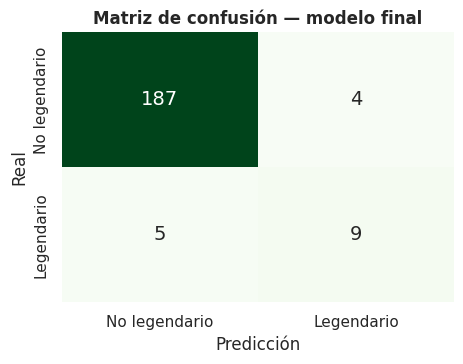

In [61]:
modelo_final = grid.best_estimator_
y_pred_final = modelo_final.predict(X_test)
y_proba_final = modelo_final.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_final, target_names=NOMBRES, digits=3))

antes_despues = pd.DataFrame({
    "Antes (parámetros iniciales)": tabla.loc[mejor_nombre, ["Accuracy", "F1 (macro)", "Recall legendario", "AUC"]],
    "Después (GridSearchCV)": [accuracy_score(y_test, y_pred_final), f1_score(y_test, y_pred_final, average="macro"),
                               recall_score(y_test, y_pred_final), roc_auc_score(y_test, y_proba_final)],
}).round(3)
display(antes_despues)

cm = confusion_matrix(y_test, y_pred_final)
fig, ax = plt.subplots(figsize=(4.8, 3.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False, ax=ax,
            xticklabels=NOMBRES, yticklabels=NOMBRES, annot_kws={"fontsize": 14})
ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
ax.set_title("Matriz de confusión — modelo final", fontweight="bold")
plt.tight_layout()
plt.show()

**Lectura:** GridSearchCV seleccionó `n_estimators=200`, `learning_rate=0.1` y `max_depth=3`, obteniendo un **F1-macro de 0.911 en validación cruzada**. En test, el modelo optimizado identificó **9 de 14 Pokémon legendarios**, igual que el modelo inicial, pero generó **4 falsas alarmas en lugar de 2**, reduciendo su F1-macro de 0.851 a 0.822.

**¿Por qué mantenemos el modelo optimizado?** Porque sus hiperparámetros fueron seleccionados mediante validación cruzada de 5 particiones sobre los 820 registros de entrenamiento, sin utilizar test para tomar decisiones. Aunque el modelo inicial obtuvo mejores métricas en test, la configuración optimizada alcanzó el mejor resultado durante la búsqueda con GridSearchCV. Esto demuestra que la optimización no garantiza una mejora en datos de prueba y que, al existir solamente 14 legendarios en test, las métricas de esta clase son sensibles a pequeñas variaciones en las predicciones.
### F.3 Serialización con `joblib.dump()`
Guardamos el **pipeline completo** (escalador + modelo): así, quien lo use no necesita escalar los datos a mano.

In [62]:
# F.3 - Guardar el modelo y su esquema de datos

artefacto = {
    "modelo": modelo_final,
    "columnas": X.columns.tolist(),
    "stats": STATS,
    "clases": NOMBRES,
    "tipos": ["type_01", "type_02"]
}

joblib.dump(artefacto, "modelo_final.joblib")

print("Modelo y esquema guardados correctamente.")
print("Archivo: modelo_final.joblib")
print("Columnas guardadas:", len(artefacto["columnas"]))
print("Tamaño:", round(
    os.path.getsize("modelo_final.joblib") / 1024, 1
), "KB")

Modelo y esquema guardados correctamente.
Archivo: modelo_final.joblib
Columnas guardadas: 44
Tamaño: 259.4 KB


### F.4 Carga con `joblib.load()` y predicción sobre nuevos datos
Simulamos que otra aplicación carga el archivo y recibe **3 Pokémon nuevos** (inventados) con sus estadísticas y tipos.

In [63]:
# F.4 - Cargar modelo y predecir nuevos Pokémon

artefacto_cargado = joblib.load("modelo_final.joblib")
modelo_cargado = artefacto_cargado["modelo"]

nuevos = pd.DataFrame({
    "nombre": ["Dragonix", "Bichito", "Rocamon"],
    "type_01": ["Dragon", "Bug", "Rock"],
    "type_02": ["Psychic", "Ninguno", "Steel"],
    "hp": [100, 40, 95],
    "attack": [120, 35, 125],
    "defense": [100, 40, 150],
    "sp_attack": [150, 20, 60],
    "sp_defense": [100, 25, 90],
    "speed": [110, 45, 50]
})

nuevos["total"] = nuevos[
    artefacto_cargado["stats"]
].sum(axis=1)

X_nuevos = pd.get_dummies(
    nuevos.drop(columns="nombre"),
    columns=artefacto_cargado["tipos"],
    dtype=int
)

X_nuevos = X_nuevos.reindex(
    columns=artefacto_cargado["columnas"],
    fill_value=0
)

nuevos["P(legendario)"] = modelo_cargado.predict_proba(
    X_nuevos
)[:, 1].round(3)

nuevos["Predicción"] = [
    artefacto_cargado["clases"][p]
    for p in modelo_cargado.predict(X_nuevos)
]

display(nuevos[
    ["nombre", "type_01", "type_02",
     "total", "P(legendario)", "Predicción"]
])

print("Modelo cargado y predicciones realizadas correctamente.")

,nombre,type_01,type_02,total,P(legendario),Predicción
0,Dragonix,Dragon,Psychic,680,0.993,Legendario
1,Bichito,Bug,Ninguno,205,0.000,No legendario
2,Rocamon,Rock,Steel,570,0.039,No legendario


Modelo cargado y predicciones realizadas correctamente.


**Lectura:** el modelo cargado desde el archivo funciona correctamente. **Dragonix** (total 680, estadísticas altas y parejas) → **Legendario** con 99 % de probabilidad. **Bichito** (total 205) → **No legendario**. Rocamon obtuvo una probabilidad estimada de 3.9 % y fue clasificado como no legendario. Este resultado demuestra que poseer estadísticas totales elevadas no garantiza una clasificación legendaria.

---
# SECCIÓN G — Conclusiones

### G.1 Resumen de resultados

Se desarrolló un pipeline de Machine Learning para clasificar Pokémon legendarios utilizando sus estadísticas y tipos. Se evaluaron seis algoritmos, destacando Gradient Boosting con una accuracy inicial de 96.6 % y un F1-macro de 0.851 en test. Mediante validación cruzada se confirmó que este modelo obtuvo el mejor rendimiento promedio entre los candidatos (0.893). Posteriormente, GridSearchCV optimizó tres hiperparámetros y alcanzó un F1-macro de 0.911 en validación cruzada. El modelo optimizado obtuvo una accuracy de 95.6 %, un F1-macro de 0.822 y un AUC de 0.946 en test, identificando 9 de 14 legendarios. Aunque no superó al modelo inicial en test, permitió seleccionar sistemáticamente sus hiperparámetros. Finalmente, el modelo y su esquema de datos se serializaron mediante joblib para realizar nuevas predicciones.

### G.2 Lecciones aprendidas
1. El accuracy no es suficiente: KNN alcanzó 93.7 % de accuracy, pero solo identificó 4 de los 14 legendarios.
2. Evitar la fuga de información: se excluyeron variables como egg_group_01, por su fuerte relación con la clase objetivo.
3. Preprocesamiento correcto: el escalador debe ajustarse únicamente con los datos de entrenamiento para evitar utilizar información del test.
4. Evaluar distintas métricas: el F1-macro, precision y recall permiten comparar mejor los modelos cuando las clases están desbalanceadas.

### G.3 Limitaciones

- **Desbalance de clases:** solo 71 de 1025 Pokémon son legendarios, con 14 casos en test, lo que afecta la estabilidad de las métricas.
- **Clasificación de míticos:** Mew, Celebi y Arceus están etiquetados como no legendarios, evidenciando que el dataset distingue a los míticos de los legendarios.
- **Similitud de estadísticas:** existen legendarios con estadísticas bajas, como Cosmog (total 200), dificultando la clasificación basada únicamente en estadísticas y tipos.
- **Calidad de datos:** se encontraron valores nulos y problemas de codificación de texto en algunas columnas originales.

G.3.1 Verificación de etiquetas y estadísticas de Pokémon míticos y legendarios

In [64]:
pokemon_revisar = ["Mew", "Arceus", "Celebi", "Cosmog"]

display(
    df.loc[
        df["name"].astype(str).str.strip().str.lower().isin(
            [p.lower() for p in pokemon_revisar]
        ),
        ["name", "is_legendary", "total"]
    ]
)

,name,is_legendary,total
150,Mew,False,600
250,Celebi,False,600
492,Arceus,False,720
788,Cosmog,True,200


### G.4 Posibles mejoras
- Revisar las etiquetas: diferenciar Pokémon normales, legendarios y míticos si el dataset permite una clasificación confiable.
- Tratar el desbalance: evaluar técnicas como SMOTE, aplicándolas únicamente al entrenamiento.
- Incorporar nuevas variables: considerar características como evolución y tasa de captura para mejorar la clasificación, evitando fuga de información.
- Ampliar la evaluación: utilizar más ejemplos de legendarios para obtener métricas más estables.